# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ahlam Idris, Geethan Sundaram, Mahati Vedula

**Date:** 11/18/2026

### Question 1

(299, 13) 

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


Missing values:  Series([], dtype: int64)
Duplicate rows:  0
Potential non-int ages:          age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
185  60.667        1                       104         1                 30   
188  60.667        1                       151         1                 40   

     high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
185                    0   389000.0               1.5           136    1   
188                    1   201000.0               1.0           136    0   

     smoking  time  DEATH_EVENT  
185        0   171            1  
188        0   172            0  


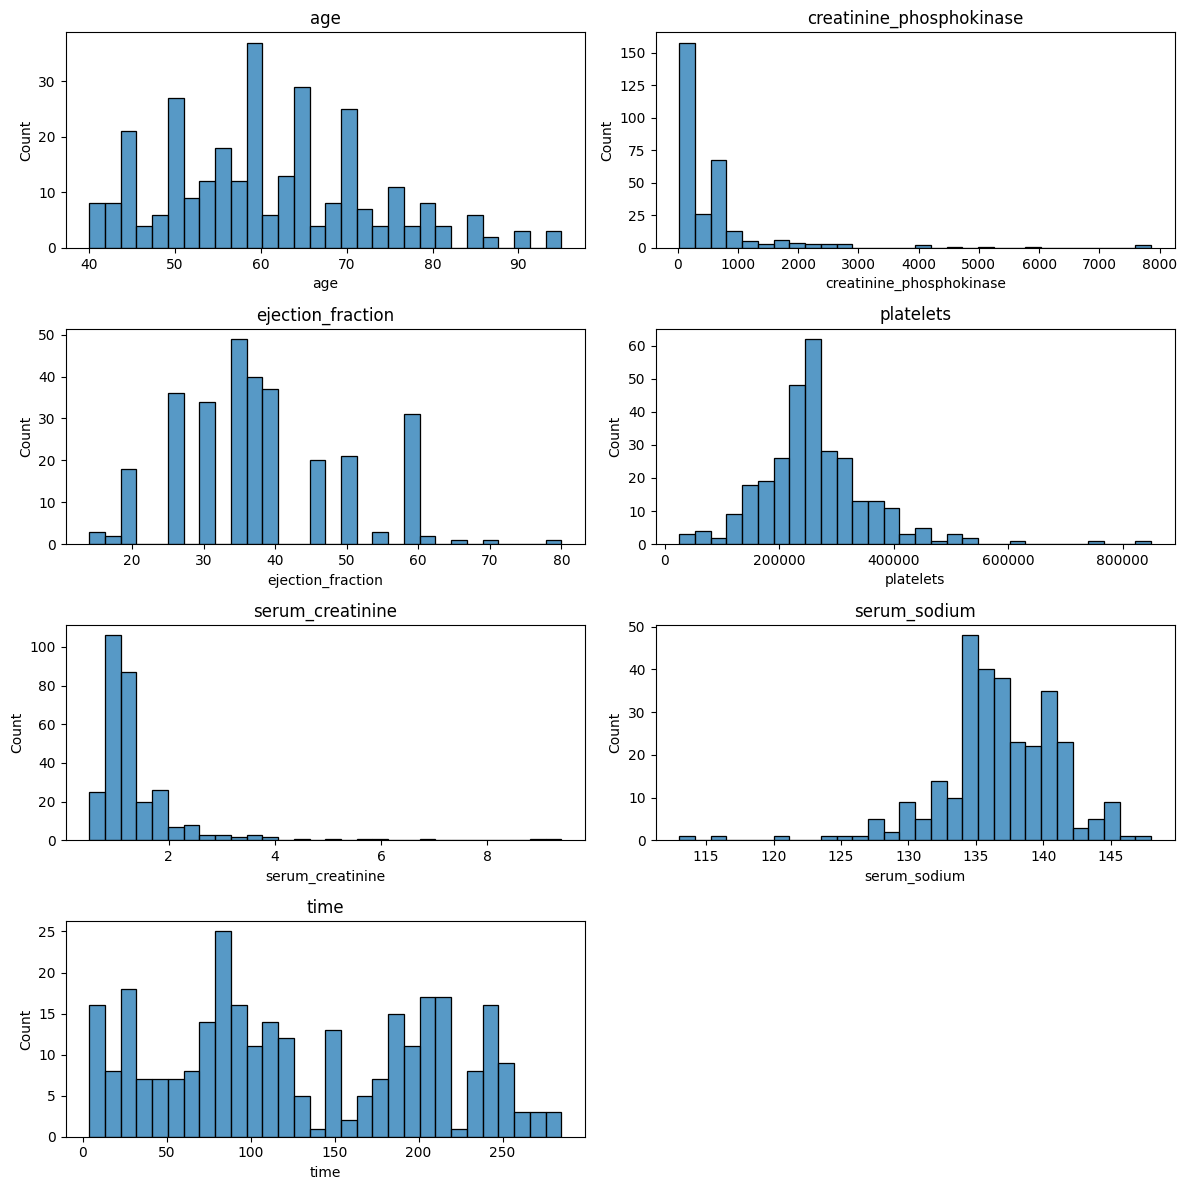

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


In [24]:
# Check out the data set `heart_failure` and appropriately clean it.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

# EDA
print(df.shape, "\n")
df.info()
display(df.head(n=15))
display(df.describe().T)
print("Missing values: ", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows: ", df.duplicated().sum())

print("Potential non-int ages: ",df[df['age'] % 1 != 0])

# Histogram
numeric_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction',
            'platelets', 'serum_creatinine', 'serum_sodium', 'time']
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for ax, c in zip(axes.ravel(), numeric_cols):
    sns.histplot(x=df[c], ax=ax, bins=30)
    ax.set_title(c)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

# Small cleaning: floor the age column to convert it to int
df['age'] = np.floor(df['age']).astype(int)
df


We noticed that the distribution for many numeric columns like creatinine_phosphokinase, serum_creatinine, and platelets are skewed right, but we decided not to exclude data entries with extreme outliers because they may be medically possible. Further research and expert consulting would need to be done to determine if these values should be excluded. Additionally, we noticed that the age variable was stored as a float64 instead of an int64, so we explored the values and found 2 decimal ages. We floored these values to be consistent and converted the whole age column to integers.

### Question 2

In [25]:
# Perform a train-test split for a specific seed (save the seed for reproducibility).
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

seed1 = 42
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed1)

# Fit a tree and a linear model on the training data and evaluate their performance on the test data.
tree = DecisionTreeClassifier(max_depth=3, random_state=seed1)
tree.fit(X_train, y_train)

linear = LinearRegression()
linear.fit(X_train, y_train)


# Set aside the predictions these models make.
prediction_tree_seed1 = tree.predict_proba(X_test)[:, 1]
prediction_linear_seed1 = linear.predict(X_test)

# Evaluation of both models
mse_tree = mean_squared_error(y_test, prediction_tree_seed1)
r2_tree = r2_score(y_test, prediction_tree_seed1)
print("Tree MSE:", mse_tree)
print("Tree R^2:", r2_tree)

mse_linear = mean_squared_error(y_test, prediction_linear_seed1)
r2_linear = r2_score(y_test, prediction_linear_seed1)
print("Linear MSE:", mse_linear)
print("Linear R^2:", r2_linear)

acc_tree = accuracy_score(y_test, prediction_tree_seed1 > 0.5)
acc_lin = accuracy_score(y_test, prediction_linear_seed1 > 0.5)
print("Tree accuracy:", acc_tree)
print("Linear accuracy:", acc_lin)

Tree MSE: 0.26359183539111136
Tree R^2: -0.08449212275200102
Linear MSE: 0.17867087264087422
Linear R^2: 0.26489698113468885
Tree accuracy: 0.6833333333333333
Linear accuracy: 0.8


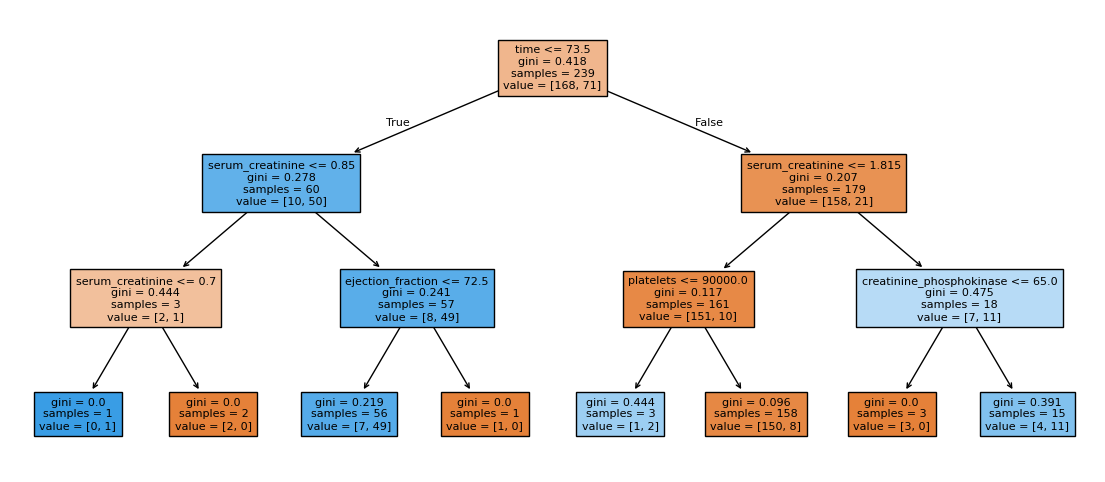

age                         0.006
anaemia                    -0.014
creatinine_phosphokinase    0.000
diabetes                    0.037
ejection_fraction          -0.009
high_blood_pressure        -0.022
platelets                  -0.000
serum_creatinine            0.107
serum_sodium               -0.006
sex                        -0.087
smoking                     0.017
time                       -0.003
dtype: float64


In [26]:
# Visual of decision tree and coefficients of linear model
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear.coef_, index=X.columns).round(3))

Using seed = 42, we saved the predictions that the tree and linear models made. We also evaluated the mean squared error, r-squared, and accuracy of both models. With an MSE of 0.18 versus 0.26, an r-squared of 0.26 versus -0.08, and an accuracy of 0.8 versus 0.68, the linear model outperformed the tree on all metrics, suggesting it is a better model.

We also visualized the decision flow of the tree. The tree splits first on time; patients followed 73.5 days or less mostly died (50/60 died), whereas patients followed longer had higher survival rates (158/179 survived). The tree then splits on serum_creatinine next for both sides. This makes sense because it is also the highest coefficient in the linear model.

### Question 3

Tree MSE: 0.10507545239572161
Tree R^2: 0.41262169468230137
Linear MSE: 0.12707510407530956
Linear R^2: 0.2896422753554122
Tree accuracy: 0.8666666666666667
Linear accuracy: 0.8833333333333333


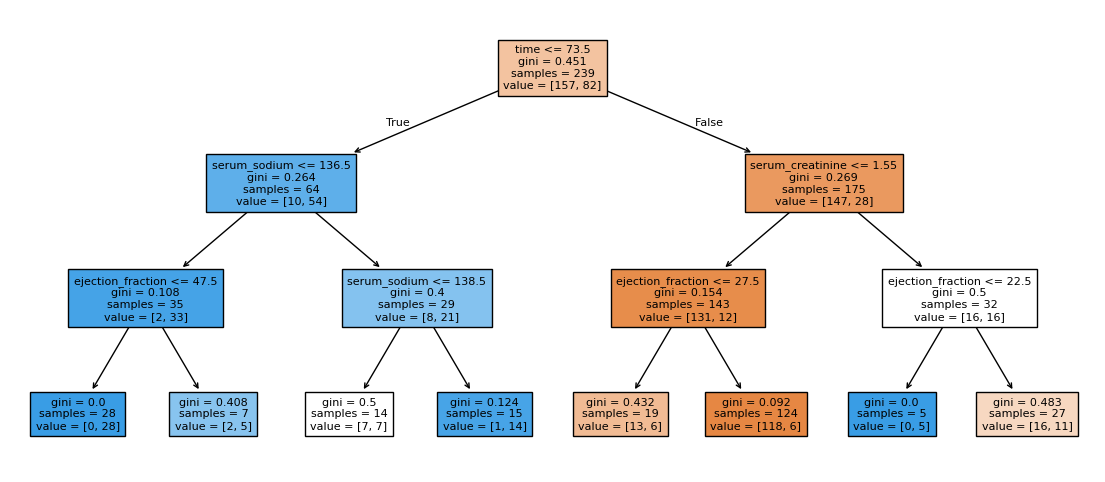

age                         0.005
anaemia                    -0.012
creatinine_phosphokinase    0.000
diabetes                    0.055
ejection_fraction          -0.010
high_blood_pressure        -0.042
platelets                  -0.000
serum_creatinine            0.091
serum_sodium               -0.008
sex                        -0.052
smoking                    -0.014
time                       -0.003
dtype: float64
Tree MSE: 0.09738569675900952
Tree R^2: 0.5203987574111705
Linear MSE: 0.11031386567951085
Linear R^2: 0.4567306204565812
Tree accuracy: 0.8833333333333333
Linear accuracy: 0.8666666666666667


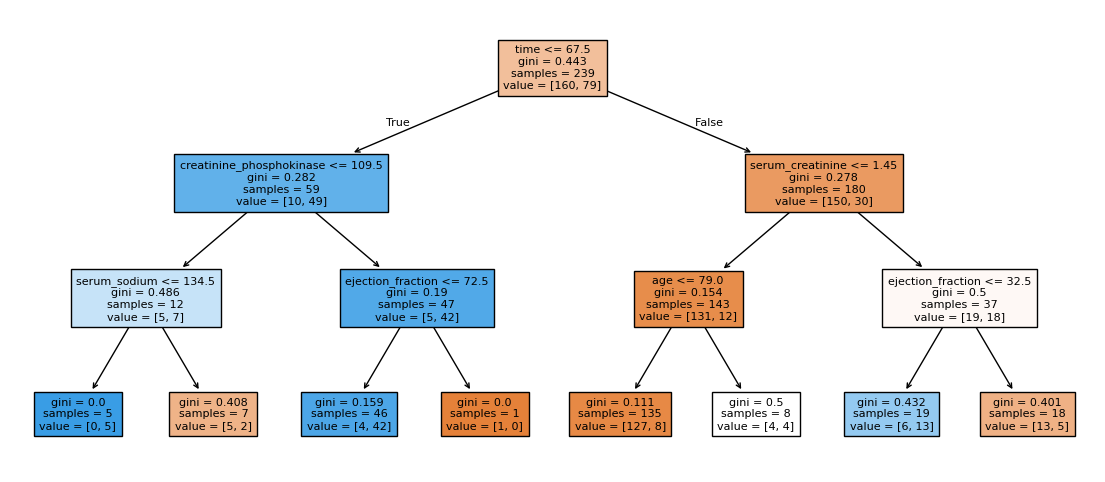

age                         0.006
anaemia                     0.006
creatinine_phosphokinase    0.000
diabetes                    0.007
ejection_fraction          -0.009
high_blood_pressure        -0.031
platelets                  -0.000
serum_creatinine            0.093
serum_sodium               -0.006
sex                        -0.075
smoking                    -0.013
time                       -0.003
dtype: float64
Tree MSE: 0.11915317694713265
Tree R^2: 0.4638107037379031
Linear MSE: 0.15099985004259767
Linear R^2: 0.3205006748083107
Tree accuracy: 0.8333333333333334
Linear accuracy: 0.8166666666666667


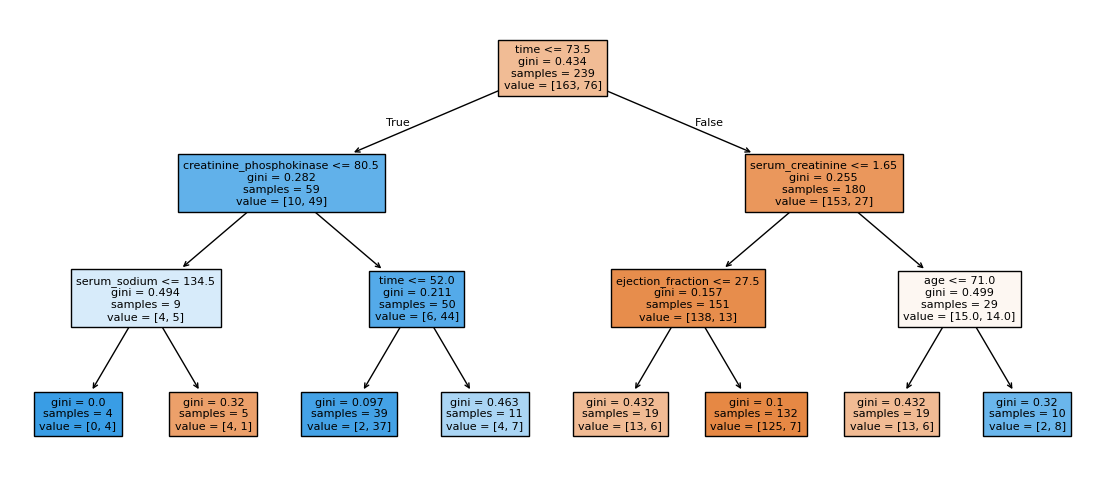

age                         0.007
anaemia                    -0.047
creatinine_phosphokinase    0.000
diabetes                    0.002
ejection_fraction          -0.011
high_blood_pressure        -0.044
platelets                  -0.000
serum_creatinine            0.072
serum_sodium               -0.008
sex                        -0.045
smoking                     0.023
time                       -0.003
dtype: float64


In [27]:
# Repeat step 2 for three to five different seeds (save the seeds for reproducibility). 
# How different are the trees that you get? Your linear model coefficients?. 
# Set aside the predictions these models make.



# ---------------- Seed 2 ----------------
seed2 = 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed2)

# Fit a tree and a linear model on the training data
tree2 = DecisionTreeClassifier(max_depth=3, random_state=seed2)
tree2.fit(X_train, y_train)

linear2 = LinearRegression()
linear2.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed2 = tree2.predict_proba(X_test)[:, 1]
prediction_linear_seed2 = linear2.predict(X_test)

# Evaluation of both models
mse_tree2 = mean_squared_error(y_test, prediction_tree_seed2)
r2_tree2 = r2_score(y_test, prediction_tree_seed2)
print("Tree MSE:", mse_tree2)
print("Tree R^2:", r2_tree2)

mse_linear2 = mean_squared_error(y_test, prediction_linear_seed2)
r2_linear2 = r2_score(y_test, prediction_linear_seed2)
print("Linear MSE:", mse_linear2)
print("Linear R^2:", r2_linear2)

acc_tree2 = accuracy_score(y_test, prediction_tree_seed2 > 0.5)
acc_lin2 = accuracy_score(y_test, prediction_linear_seed2 > 0.5)
print("Tree accuracy:", acc_tree2)
print("Linear accuracy:", acc_lin2)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree2, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear2.coef_, index=X.columns).round(3))

# ---------------- Seed 3 ----------------
seed3 = 2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed3)

# Fit a tree and a linear model on the training data
tree3 = DecisionTreeClassifier(max_depth=3, random_state=seed3)
tree3.fit(X_train, y_train)

linear3 = LinearRegression()
linear3.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed3 = tree3.predict_proba(X_test)[:, 1]
prediction_linear_seed3 = linear3.predict(X_test)

# Evaluation of both models
mse_tree3 = mean_squared_error(y_test, prediction_tree_seed3)
r2_tree3 = r2_score(y_test, prediction_tree_seed3)
print("Tree MSE:", mse_tree3)
print("Tree R^2:", r2_tree3)

mse_linear3 = mean_squared_error(y_test, prediction_linear_seed3)
r2_linear3 = r2_score(y_test, prediction_linear_seed3)
print("Linear MSE:", mse_linear3)
print("Linear R^2:", r2_linear3)

acc_tree3 = accuracy_score(y_test, prediction_tree_seed3 > 0.5)
acc_lin3 = accuracy_score(y_test, prediction_linear_seed3 > 0.5)
print("Tree accuracy:", acc_tree3)
print("Linear accuracy:", acc_lin3)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree3, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear3.coef_, index=X.columns).round(3))

# ---------------- Seed 4 ----------------
seed4 = 3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed4)

# Fit a tree and a linear model on the training data
tree4 = DecisionTreeClassifier(max_depth=3, random_state=seed4)
tree4.fit(X_train, y_train)

linear4 = LinearRegression()
linear4.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed4 = tree4.predict_proba(X_test)[:, 1]
prediction_linear_seed4 = linear4.predict(X_test)

# Evaluation of both models
mse_tree4 = mean_squared_error(y_test, prediction_tree_seed4)
r2_tree4 = r2_score(y_test, prediction_tree_seed4)
print("Tree MSE:", mse_tree4)
print("Tree R^2:", r2_tree4)

mse_linear4 = mean_squared_error(y_test, prediction_linear_seed4)
r2_linear4 = r2_score(y_test, prediction_linear_seed4)
print("Linear MSE:", mse_linear4)
print("Linear R^2:", r2_linear4)

acc_tree4 = accuracy_score(y_test, prediction_tree_seed4 > 0.5)
acc_lin4 = accuracy_score(y_test, prediction_linear_seed4 > 0.5)
print("Tree accuracy:", acc_tree4)
print("Linear accuracy:", acc_lin4)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree4, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear4.coef_, index=X.columns).round(3))

In [28]:
# Comparing linear model coefficients across seeds
coef_table = pd.DataFrame({
    "seed 42": linear.coef_,
    "seed 1": linear2.coef_,
    "seed 2": linear3.coef_,
    "seed 3": linear4.coef_
}, index=X.columns)
display(coef_table.round(3))

# Comparing performance across seeds
results = pd.DataFrame({
    "seed": [42, 1, 2, 3],
    "tree MSE": [mse_tree, mse_tree2, mse_tree3, mse_tree4],
    "linear MSE": [mse_linear, mse_linear2, mse_linear3, mse_linear4],
    "tree R^2": [r2_tree, r2_tree2, r2_tree3, r2_tree4],
    "linear R^2": [r2_linear, r2_linear2, r2_linear3, r2_linear4],
    "tree accuracy": [acc_tree, acc_tree2, acc_tree3, acc_tree4],
    "linear accuracy": [acc_lin, acc_lin2, acc_lin3, acc_lin4]
})
display(results.round(3))

,seed 42,seed 1,seed 2,seed 3
age,0.006,0.005,0.006,0.007
anaemia,-0.014,-0.012,0.006,-0.047
creatinine_phosphokinase,0.000,0.000,0.000,0.000
diabetes,0.037,0.055,0.007,0.002
ejection_fraction,-0.009,-0.010,-0.009,-0.011
high_blood_pressure,-0.022,-0.042,-0.031,-0.044
platelets,-0.000,-0.000,-0.000,-0.000
serum_creatinine,0.107,0.091,0.093,0.072
serum_sodium,-0.006,-0.008,-0.006,-0.008
sex,-0.087,-0.052,-0.075,-0.045


,seed,tree MSE,linear MSE,tree R^2,linear R^2,tree accuracy,linear accuracy
0,42,0.264,0.179,-0.084,0.265,0.683,0.800
1,1,0.105,0.127,0.413,0.290,0.867,0.883
2,2,0.097,0.110,0.520,0.457,0.883,0.867
3,3,0.119,0.151,0.464,0.321,0.833,0.817


*Seed 1*: With seed = 1, the tree achieved an MSE of 0.11 versus 0.13 for the linear model, an R² of 0.41 versus 0.29, and an accuracy of 0.87 versus 0.88. The tree did better on MSE and R², while the linear model was slightly more accurate. The tree splits first on time (73.5 days or less mostly died, or 54/64 patients). On the short-follow-up side it then splits on serum_sodium and ejection_fraction, and on the long-follow-up side it splits on serum_creatinine and ejection_fraction.

*Seed 2*: With seed = 2, the tree achieved an MSE of 0.10 versus 0.11, an R² of 0.52 versus 0.46, and an accuracy of 0.88 versus 0.87. The tree performed slightly better on all three metrics. It splits first on time again, but at a different cutoff (67.5 days). The next splits are creatinine_phosphokinase and serum_creatinine, and a split on age appears lower down.

*Seed 3*: With seed = 3, the tree achieved an MSE of 0.12 versus 0.15, an R² of 0.46 versus 0.32, and an accuracy of 0.83 versus 0.82. The tree again outperformed the linear model on all metrics. It splits first on time (73.5), then on creatinine_phosphokinase and serum_creatinine, with further splits on time, ejection_fraction and age.

*Takeaways*: The time is always the tree root and first split, although the split point changes a couple of days between trees. Below this, the second-level split and beyond change a lot between trees. The trees look different seed-to-seed. The first tree, seed=42, might have been an unlucky pick becuase the linear model outperformed the tree in this instance, but the tree is a stronger model for all the other seeds (3/4 seeds, or 75% of the time).

### Question 4

### Question 5

### Question 6

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### Question 1

### Question 2

### Question 3

### Question 4

### Question 5

### Question 6

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]